<a href="https://colab.research.google.com/github/BitCurrent02/DSP-Course-2026/blob/main/LAB-11-Studded-Tire-Checkpoint/studded_tire_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Studded Tire Checkpoint – Student Starter Notebook
**DSP – Image Processing Final Project**

Read the assignment on Moodle first. This notebook gives you the structure, the data loading and the evaluation helpers. **You implement the parts marked `TODO`** (they raise `NotImplementedError` until you do).

**How to work**
1. In Colab upload `dataset_v2_split.zip` and `best.pt` to `/content` (or mount Drive) and set the paths in the CONFIG cell.
2. Run the cells top to bottom. Implement the helper functions in the *helper library* cell first; the **self-check** cell below it tells you whether they behave correctly.
3. After each part write your answers in the **✏️ Your answer** cells and add your own figures where the assignment asks for them.
4. Parameters are tuned on **validation** only. The test set is used for the final numbers.
5. You may add cells, but do not change the given helper functions, the seeds, or the original data.

Report failures honestly. You must be able to explain every line you submit.

## Part 0 – Setup and data audit

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

os.listdir('/content/drive/MyDrive/LAB 11 - Studded Tire Checkpoint')

['studded_tire_student_starter.ipynb',
 'best.pt',
 'dataset_v2_split-20261125T220825Z-1-001.zip']

In [4]:
!pip -q install ultralytics scikit-image
import os, zipfile, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display

In [39]:
import re, random, time
import numpy as np, cv2
from pathlib import Path
from skimage.feature import hog
from skimage.metrics import peak_signal_noise_ratio as psnr_fn, structural_similarity as ssim_fn
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

SEED = 42

# ---------- Part 1: classical toolbox ----------
def clahe_gray(g, clip=2.0, tile=8):
    return cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(g)

def stud_candidates(bgr, tophat_k=25, min_thr=80, min_area=10, max_area=100, debug=False):
    """Classical stud-candidate detector.
    Returns [count, mean_area, std_area, area_fraction] (area_fraction = total candidate area / image area).
    If debug=True return (feats, tophat_img, binary_img, list_of_centroids) instead.

    TODO - suggested pipeline:
      1. BGR -> gray, then CLAHE (clahe_gray)
      2. white top-hat with an elliptical structuring element of size tophat_k x tophat_k  (cv2.morphologyEx, cv2.MORPH_TOPHAT)
      3. threshold = max(Otsu threshold of the top-hat image, min_thr)
      4. cv2.connectedComponentsWithStats on the binary image
      5. keep components with min_area <= area <= max_area; compute the 4 numbers (use 0.0 if nothing is kept)
    """
    # 1. Grayscale and CLAHE
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    enhanced = clahe_gray(gray)

    # 2. White top-hat
    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (tophat_k, tophat_k))
    tophat = cv2.morphologyEx(enhanced, cv2.MORPH_TOPHAT, kernel)

    # 3. Thresholding
    otsu, _ = cv2.threshold(tophat, 0, 255,
                            cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    threshold = max(otsu, min_thr)
    _, binary = cv2.threshold(tophat, threshold, 255,
                              cv2.THRESH_BINARY)

    # Brightness filter
    binary[gray < 160] = 0

    # 4. Connected components
    num_labels, labels, stats, centroids = \
        cv2.connectedComponentsWithStats(binary)

    # 5. Size and shape filter
    areas = []
    centers = []

    for i in range(1, num_labels):
        area = stats[i, cv2.CC_STAT_AREA]
        w = stats[i, cv2.CC_STAT_WIDTH]
        h = stats[i, cv2.CC_STAT_HEIGHT]

        if min_area <= area <= max_area:
            if min(w, h) / max(w, h) >= 0.6:
                if area / (w * h) >= 0.5:
                    areas.append(area)
                    centers.append(centroids[i])

    count = len(areas)
    mean_area = np.mean(areas) if count > 0 else 0.0
    std_area = np.std(areas) if count > 0 else 0.0
    area_fraction = np.sum(areas) / gray.size

    feats = [count, mean_area, std_area, area_fraction]

    if debug:
        return feats, tophat, binary, centers

    return feats

def classical_features(bgr):
    """Feature vector = stud_candidates(bgr) (4 numbers) followed by a HOG descriptor.
    TODO: resize to 128x128, grayscale, CLAHE, then skimage.feature.hog with orientations=9,
    pixels_per_cell=(16, 16), cells_per_block=(2, 2). Return one 1-D numpy array (1768 values)."""
    blobs = stud_candidates(bgr)

    resized = cv2.resize(bgr, (128, 128))
    gray = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)
    gray = clahe_gray(gray)

    hog_features = hog(gray, orientations=9,
                       pixels_per_cell=(16, 16),
                       cells_per_block=(2, 2))

    return np.concatenate((blobs, hog_features))

# ---------- Part 4: degradations ----------
def motion_psf(L):
    """Horizontal motion-blur kernel: a 1 x L float32 array, every element 1/L (so it sums to 1)."""
    return np.ones((1, L), np.float32) / L

def motion_blur(img, L):
    """Blur img with the horizontal line kernel of length L.
    TODO: cv2.filter2D with motion_psf(L) and borderType=cv2.BORDER_REFLECT. Output stays uint8."""
    return cv2.filter2D(img, -1, motion_psf(L),
                        borderType=cv2.BORDER_REFLECT)

def darken(img, gamma):
    """Gamma darkening: out = 255 * (img/255) ** gamma, clipped to 0..255, returned as uint8 (gamma > 1 darkens)."""
    out = 255 * (img / 255.0) ** gamma
    return np.clip(np.round(out), 0, 255).astype(np.uint8)

def add_noise(img, sigma, rng):
    """Add zero-mean Gaussian noise with standard deviation sigma (grey levels).
    Use the given numpy Generator `rng` (rng.normal), clip to 0..255, round, return uint8."""
    noise = rng.normal(0, sigma, img.shape)
    out = img + noise
    return np.clip(np.round(out), 0, 255).astype(np.uint8)

def build_conditions():
    C = {"original": lambda im, r: im}
    for L in (5, 15, 25, 35):
        C[f"blur_L{L}"] = lambda im, r, L=L: motion_blur(im, L)
    for g, s in ((1.5, 5), (2.5, 15)):
        C[f"dark_g{g}_s{s}"] = lambda im, r, g=g, s=s: add_noise(darken(im, g), s, r)
    C["combined"] = lambda im, r: add_noise(darken(motion_blur(im, 15), 2.0), 10, r)
    return C

def degrade_set(imgs, fn, seed=SEED):
    return [fn(im, np.random.default_rng(seed + i)) for i, im in enumerate(imgs)]

# ---------- Part 5: restoration ----------
def psf2otf(psf, shape):
    big = np.zeros(shape, np.float32)
    h, w = psf.shape
    big[:h, :w] = psf
    return np.fft.fft2(np.roll(big, (-(h // 2), -(w // 2)), axis=(0, 1)))

def wiener_deconv(img, psf, K):
    """Frequency-domain Wiener deconvolution, applied to each colour channel separately.
        W(u,v) = conj(H) / (|H|^2 + K)          H = psf2otf(psf, image shape)  (given above)
        restored = real( ifft2( fft2(channel) * W ) )
    K is the noise-to-signal ratio. Clip to 0..255 and return uint8 with the same shape as img.
    TODO: implement with np.fft (it must work for 3-channel images)."""
    H = psf2otf(psf, img.shape[:2])
    W = np.conj(H) / (np.abs(H)**2 + K)

    restored = np.zeros(img.shape, np.float32)

    for c in range(img.shape[2]):
        restored[:, :, c] = np.real(
            np.fft.ifft2(np.fft.fft2(img[:, :, c]) * W))

    return np.clip(restored, 0, 255).astype(np.uint8)

def clahe_bgr(img, clip=2.0):
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    lab[..., 0] = clahe_gray(lab[..., 0], clip)
    return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)

def restore_lowlight(img, gamma, denoise_h=5, use_clahe=True):
    """Low-light restoration.
    TODO: (1) undo the darkening with darken(img, 1/gamma); (2) denoise with cv2.fastNlMeansDenoisingColored(out, None, h, h, 7, 21);
    (3) if use_clahe: apply clahe_bgr. Return uint8 BGR."""
    out = darken(img, 1/gamma)

    out = cv2.fastNlMeansDenoisingColored(
        out, None, denoise_h, denoise_h, 7, 21)

    if use_clahe:
        out = clahe_bgr(out)

    return out

def psnr_ssim(ref, test):
    return (psnr_fn(ref, test, data_range=255),
            ssim_fn(ref, test, data_range=255, channel_axis=2))

# ---------- metrics ----------
def metrics(y, p):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average="binary", pos_label=1, zero_division=0)
    return dict(accuracy=accuracy_score(y, p), precision=pr, recall=rc, f1=f1)

def bootstrap_ci(y, p, n=1000, seed=SEED, alpha=0.05):
    rng = np.random.default_rng(seed)
    y, p = np.asarray(y), np.asarray(p)
    accs = [np.mean(y[i] == p[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(n))]
    return tuple(np.quantile(accs, [alpha / 2, 1 - alpha / 2]))

def threshold_for_precision(y, score, target=0.95):
    ts = np.unique(score)
    ok = [t for t in ts if (score >= t).sum() and np.mean(y[score >= t] == 1) >= target]
    return min(ok) if ok else 0.5

In [40]:
# ===== SELF-CHECK: run after implementing the helper functions =====
def _check(name, fn):
    try:
        ok = bool(fn()); print(("PASS  " if ok else "FAIL  ") + name)
    except NotImplementedError:
        print("TODO  " + name)
    except Exception as e:
        print(f"ERROR {name}: {type(e).__name__}: {e}")

_rng = np.random.default_rng(0)
_img = np.full((200, 260, 3), 70, np.uint8); cv2.circle(_img, (130, 100), 80, (25, 25, 25), -1)
for a in np.linspace(0, 6.28, 24): cv2.circle(_img, (int(130 + 60 * np.cos(a)), int(100 + 60 * np.sin(a))), 3, (230, 230, 230), -1)

_check("motion_psf: shape (1, L) and sums to 1", lambda: motion_psf(15).shape == (1, 15) and abs(float(motion_psf(15).sum()) - 1) < 1e-5)
_check("motion_blur: uint8, same shape, smoother than input", lambda: (lambda b: b.dtype == np.uint8 and b.shape == _img.shape and
       np.abs(np.diff(b.astype(int), axis=1)).mean() < np.abs(np.diff(_img.astype(int), axis=1)).mean())(motion_blur(_img, 15)))
_check("darken: uint8, darker, gamma=1 leaves image unchanged", lambda: darken(_img, 2.0).dtype == np.uint8 and darken(_img, 2.0).mean() < _img.mean() and np.array_equal(darken(_img, 1.0), _img))
_check("add_noise: uint8, noise std close to sigma", lambda: (lambda n: n.dtype == np.uint8 and 8 < (n.astype(float) - 128).std() < 12)(add_noise(np.full((200, 200, 3), 128, np.uint8), 10, np.random.default_rng(1))))
_check("add_noise: same seed gives same result", lambda: np.array_equal(add_noise(_img, 10, np.random.default_rng(5)), add_noise(_img, 10, np.random.default_rng(5))))
_check("wiener_deconv: improves PSNR of a blurred image (known kernel)", lambda: (lambda b: psnr_ssim(_img, wiener_deconv(b, motion_psf(15), 1e-3))[0] > psnr_ssim(_img, b)[0])(motion_blur(_img, 15)))
_check("wiener_deconv: uint8 and same shape", lambda: (lambda r: r.dtype == np.uint8 and r.shape == _img.shape)(wiener_deconv(motion_blur(_img, 15), motion_psf(15), 1e-3)))
_check("stud_candidates: returns 4 numbers, finds blobs on the test pattern", lambda: (lambda f: len(f) == 4 and f[0] >= 10)(stud_candidates(_img)))
_check("classical_features: 1-D vector of length 1768", lambda: classical_features(_img).shape == (1768,))
_check("restore_lowlight: uint8, brighter than the dark input", lambda: (lambda d: restore_lowlight(d, 2.0).dtype == np.uint8 and restore_lowlight(d, 2.0).mean() > d.mean())(darken(_img, 2.0)))

PASS  motion_psf: shape (1, L) and sums to 1
PASS  motion_blur: uint8, same shape, smoother than input
PASS  darken: uint8, darker, gamma=1 leaves image unchanged
PASS  add_noise: uint8, noise std close to sigma
PASS  add_noise: same seed gives same result
PASS  wiener_deconv: improves PSNR of a blurred image (known kernel)
PASS  wiener_deconv: uint8 and same shape
PASS  stud_candidates: returns 4 numbers, finds blobs on the test pattern
PASS  classical_features: 1-D vector of length 1768
PASS  restore_lowlight: uint8, brighter than the dark input


In [6]:
# ===== CONFIG: edit these paths =====
ZIP_PATH   = "/content/drive/MyDrive/LAB 11 - Studded Tire Checkpoint/dataset_v2_split-20261125T220825Z-1-001.zip"
MODEL_PATH = "/content/drive/MyDrive/LAB 11 - Studded Tire Checkpoint/best.pt"
WORK       = Path("/content/data")
MAX_SIDE   = 512
POS_NAME   = "st"
# ====================================
random.seed(SEED); np.random.seed(SEED)
src = WORK / "original"
if not src.exists():
    src.mkdir(parents=True)
    with zipfile.ZipFile(ZIP_PATH) as z: z.extractall(src)

def find_splits(root):
    found = {}
    for p in sorted(Path(root).rglob("*"), key=lambda p: len(p.parts)):
        n = {"valid": "val", "validation": "val"}.get(p.name.lower(), p.name.lower())
        if p.is_dir() and n in ("train", "val", "test") and n not in found: found[n] = p
    return found

SPLIT_DIRS = find_splits(src)
print({k: str(v) for k, v in SPLIT_DIRS.items()})
assert set(SPLIT_DIRS) == {"train", "val", "test"}, "Could not find train/val/test folders - check the zip structure"

CLASS_NAMES = sorted(d.name for d in SPLIT_DIRS["train"].iterdir() if d.is_dir())
norm = lambda s: re.sub("[^a-z]", "", s.lower())
if POS_NAME is None:
    cand = [c for c in CLASS_NAMES if not re.match(r"(non|no|un|without)", norm(c))]
    assert len(cand) == 1, f"Set POS_NAME manually, classes: {CLASS_NAMES}"
    POS_NAME = cand[0]
NEG_NAME = [c for c in CLASS_NAMES if c != POS_NAME][0]
print("classes:", CLASS_NAMES, "| positive (studded) =", POS_NAME)

def load_split(split):
    imgs, y, paths = [], [], []
    for lab, cname in ((0, NEG_NAME), (1, POS_NAME)):
        for f in sorted((SPLIT_DIRS[split] / cname).glob("*")):
            if f.suffix.lower() not in (".jpg", ".jpeg", ".png", ".bmp", ".webp"): continue
            im = cv2.imread(str(f))
            if im is None: continue
            s = MAX_SIDE / max(im.shape[:2])
            if s < 1: im = cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
            imgs.append(im); y.append(lab); paths.append(f)
    return dict(imgs=imgs, y=np.array(y), paths=paths)

DATA = {s: load_split(s) for s in ("train", "val", "test")}
audit = pd.DataFrame({s: {"n_images": len(d["y"]), "studded": int(d["y"].sum()), "non-studded": int((d["y"] == 0).sum()),
                          "median_size (HxW)": "x".join(str(int(v)) for v in np.median([i.shape[:2] for i in d["imgs"]], 0))} for s, d in DATA.items()}).T
display(audit)

{'test': '/content/data/original/dataset_v2_split/test', 'val': '/content/data/original/dataset_v2_split/val', 'train': '/content/data/original/dataset_v2_split/train'}
classes: ['nst', 'st'] | positive (studded) = st


,n_images,studded,non-studded,median_size (HxW)
train,350,175,175,261x261
val,76,38,38,261x261
test,74,37,37,261x261


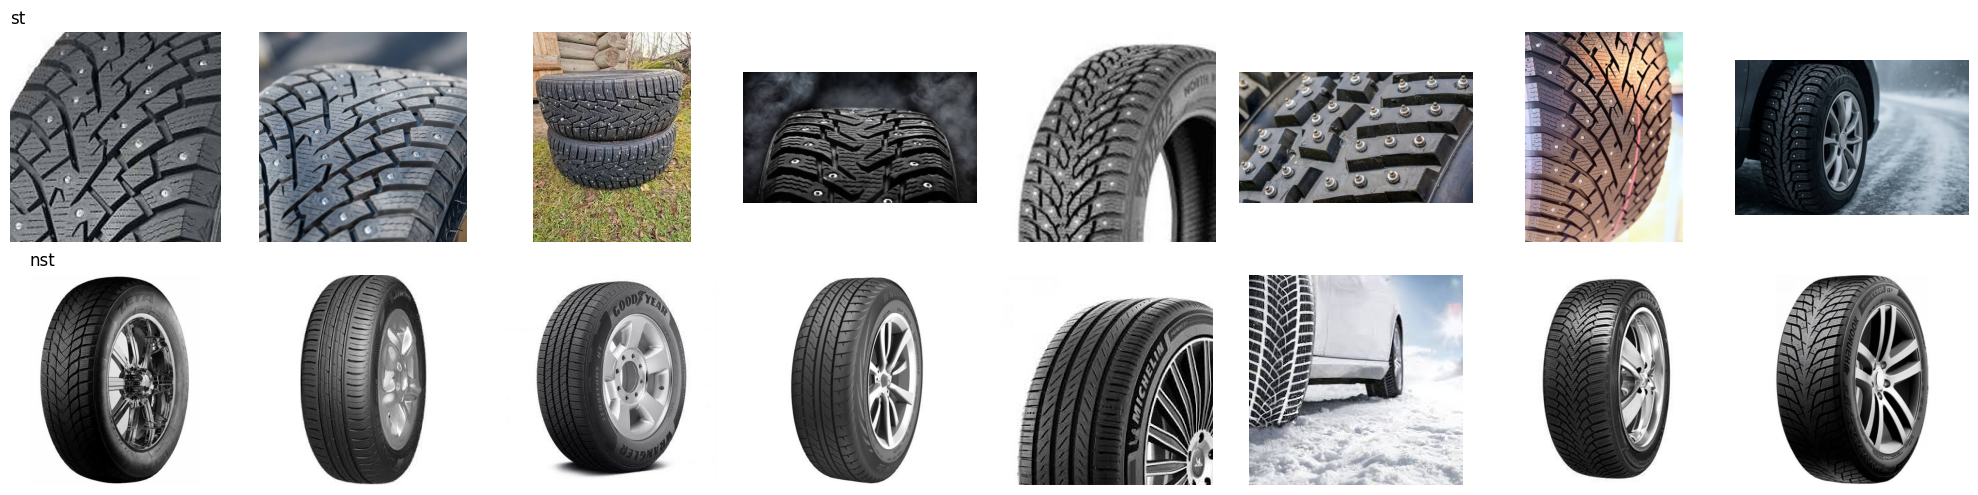

In [7]:
# image grid: 8 per class (train)
fig, ax = plt.subplots(2, 8, figsize=(20, 5))
for r, lab in enumerate((1, 0)):
    idx = np.where(DATA["train"]["y"] == lab)[0][:8]
    for c, i in enumerate(idx):
        ax[r, c].imshow(cv2.cvtColor(DATA["train"]["imgs"][i], cv2.COLOR_BGR2RGB)); ax[r, c].axis("off")
    ax[r, 0].set_title(POS_NAME if lab else NEG_NAME, loc="left")
plt.tight_layout(); plt.show()

**Write (3 sentences):** name three characteristics that make this task hard (e.g. stud size vs. image size, reflections on wet tires, tire tread patterns that look like studs, viewing angle).

✏️ **Your answer:**

1.   The first characteristic that makes this hard are the different viewing angles and also the distances.
2.   The Second one is the diferent lightning condition. Some pictures are birghter, some are darker or have reflections.
3.   The third condition is that they have diferent profils and sometimes there is also snow.

In [8]:
#Create seperate folders for each experiment
(WORK / "blur").mkdir(exist_ok=True)
(WORK / "lowlight").mkdir(exist_ok=True)
(WORK / "restored").mkdir(exist_ok=True)

## Part 1 – Classical image processing toolbox

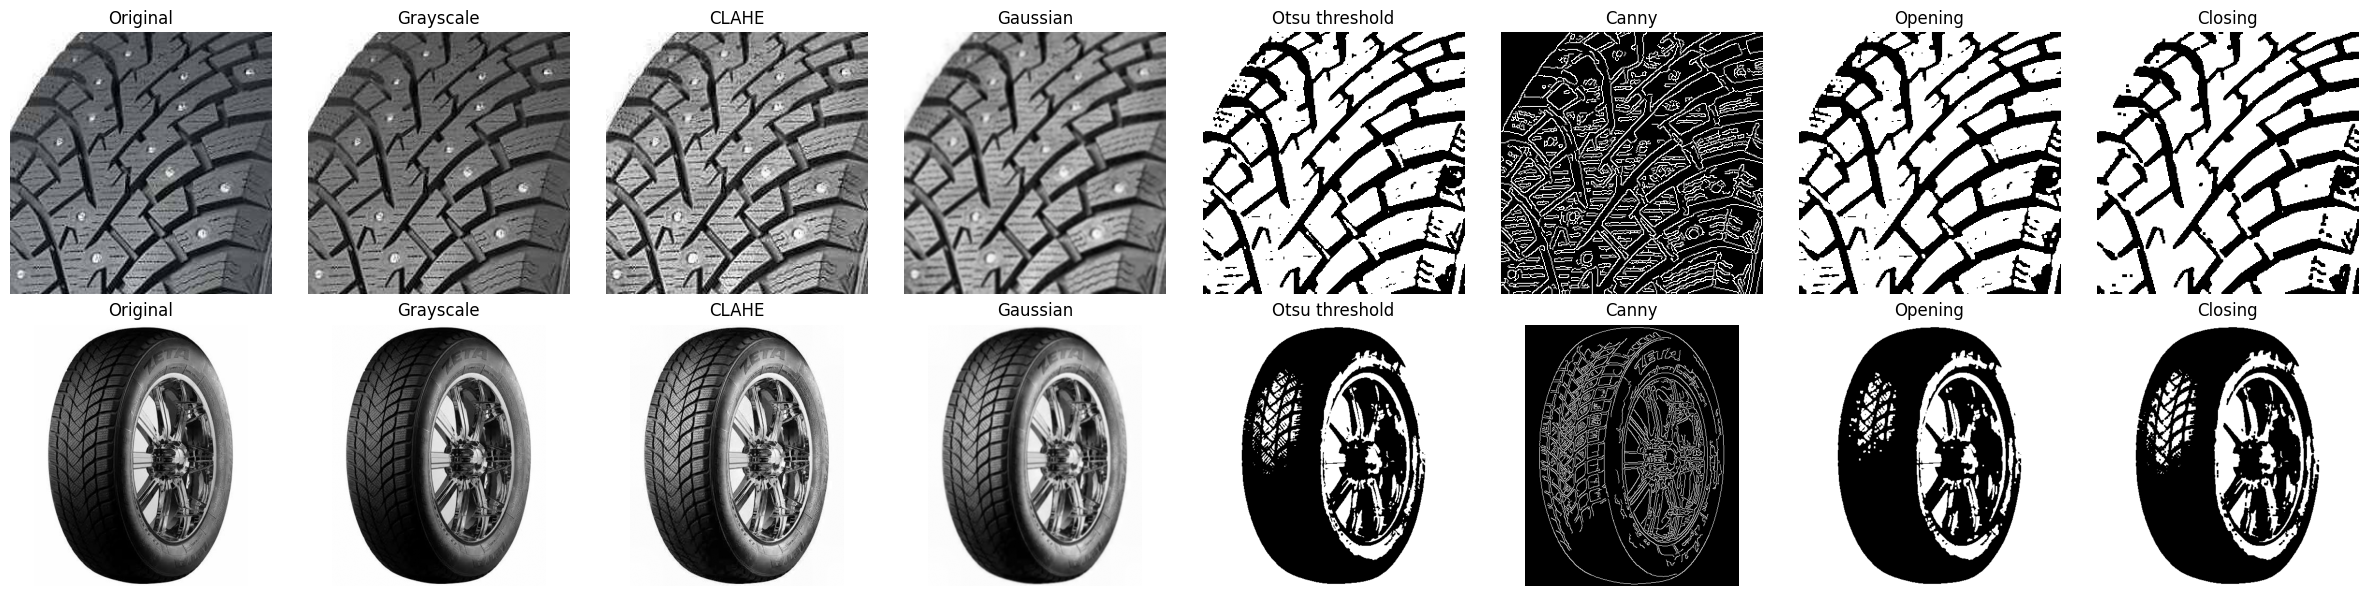

In [9]:
def toolbox(bgr):
    # Return a list of (name, image) pairs, in this order:
    # original (convert to RGB for display), gray, CLAHE, Gaussian (5x5), Otsu threshold, Canny, opening, closing.
    # Use the OpenCV functions from the lecture; choose your own parameters and keep them reasonable.
    # TODO
    original = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    clahe = clahe_gray(gray)
    gaussian = cv2.GaussianBlur(clahe, (5, 5), 0)

    _, threshold = cv2.threshold(gaussian, 0, 255,
                                cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    canny = cv2.Canny(gaussian, 50, 150)

    kernel = np.ones((3, 3), np.uint8)
    opening = cv2.morphologyEx(threshold, cv2.MORPH_OPEN, kernel)
    closing = cv2.morphologyEx(threshold, cv2.MORPH_CLOSE, kernel)

    return [("Original", original),
            ("Grayscale", gray),
            ("CLAHE", clahe),
            ("Gaussian", gaussian),
            ("Otsu threshold", threshold),
            ("Canny", canny),
            ("Opening", opening),
            ("Closing", closing)]

ex = {lab: np.where(DATA["train"]["y"] == lab)[0][0] for lab in (1, 0)}
fig, ax = plt.subplots(2, 8, figsize=(24, 6))
for r, lab in enumerate((1, 0)):
    for c, (name, im) in enumerate(toolbox(DATA["train"]["imgs"][ex[lab]])):
        ax[r, c].imshow(im, cmap=None if im.ndim == 3 else "gray"); ax[r, c].set_title(name); ax[r, c].axis("off")
plt.tight_layout(); plt.show()

### Stud candidate detector
`stud_candidates()` = CLAHE → white top-hat → Otsu threshold → connected components → size filter.
**Task:** tune `tophat_k`, `min_area`, `max_area` on the **validation** set (do not touch test), then compare candidate counts of both classes.

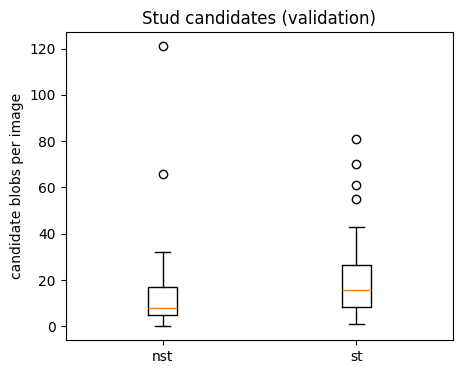

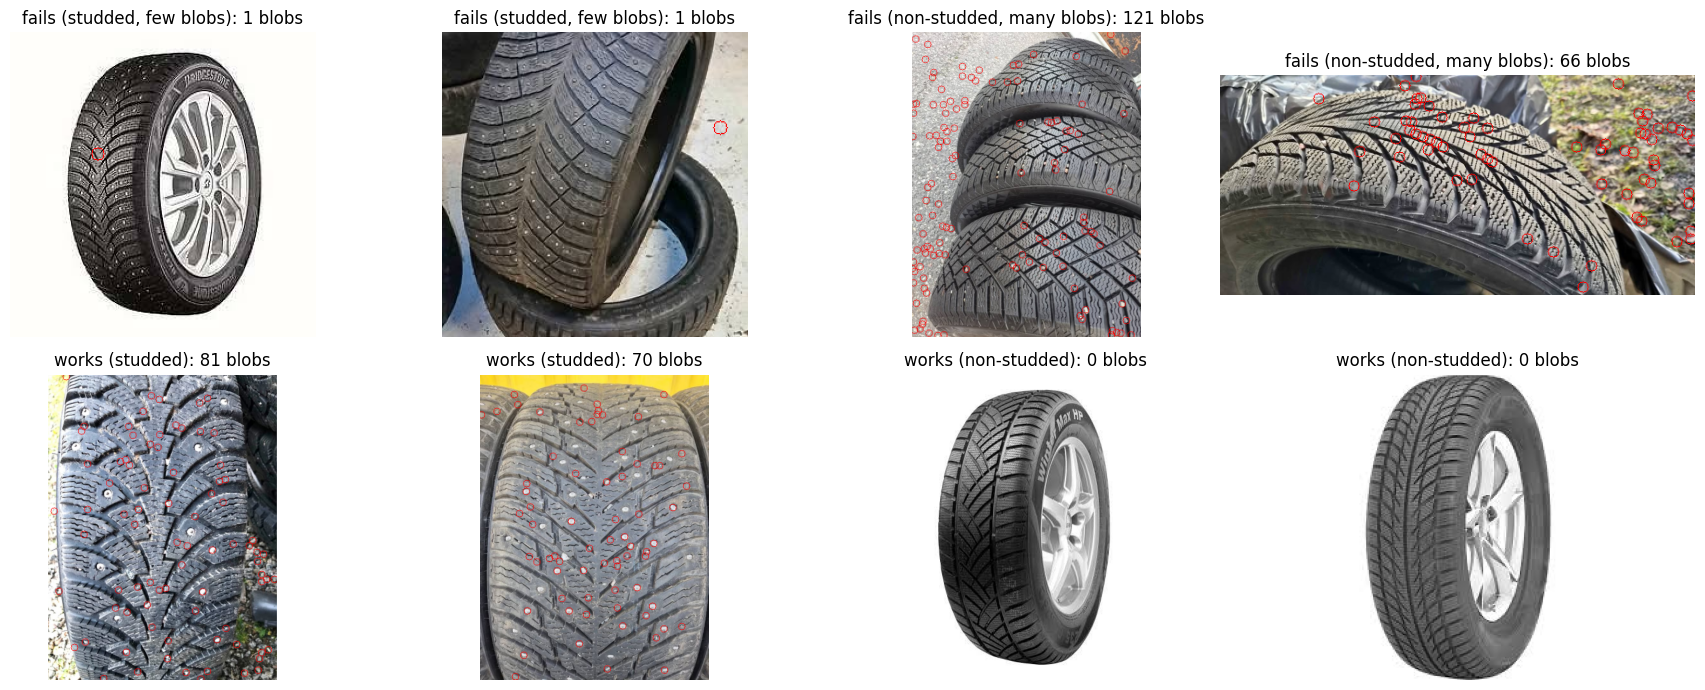

In [31]:
cnt = {s: np.array([stud_candidates(im)[0] for im in DATA[s]["imgs"]]) for s in ("train", "val")}
plt.figure(figsize=(5, 4))
plt.boxplot([cnt["val"][DATA["val"]["y"] == 0], cnt["val"][DATA["val"]["y"] == 1]]); plt.xticks([1, 2], [NEG_NAME, POS_NAME])
plt.ylabel("candidate blobs per image"); plt.title("Stud candidates (validation)"); plt.show()

# 2 successes and 2 failures: studded images with the fewest blobs / non-studded with the most
v = DATA["val"]; pos = np.where(v["y"] == 1)[0]; neg = np.where(v["y"] == 0)[0]
picks = [("works (studded)", pos[np.argsort(-cnt["val"][pos])[:2]]), ("fails (studded, few blobs)", pos[np.argsort(cnt["val"][pos])[:2]]),
         ("works (non-studded)", neg[np.argsort(cnt["val"][neg])[:2]]), ("fails (non-studded, many blobs)", neg[np.argsort(-cnt["val"][neg])[:2]])]
fig, ax = plt.subplots(2, 4, figsize=(18, 7)); k = 0
for title, idxs in picks[1:2] + picks[3:4] + picks[0:1] + picks[2:3]:
    for i in idxs:
        feats, th, bw, cen = stud_candidates(v["imgs"][i], debug=True)
        im = cv2.cvtColor(v["imgs"][i].copy(), cv2.COLOR_BGR2RGB)
        for (x, y_) in cen: cv2.circle(im, (int(x), int(y_)), 6, (255, 0, 0), 1)
        ax[k // 4, k % 4].imshow(im); ax[k // 4, k % 4].set_title(f"{title}: {feats[0]} blobs"); ax[k // 4, k % 4].axis("off"); k += 1
plt.tight_layout(); plt.show()

**Write:** why does the detector succeed on some images and fail on others? (Think: wet reflections, tread edges, shadows, stud size in pixels.)

**Parameter tuning:**

I tested different parameters on the validation set and added a brightness and shape filter to reduce unwanted candidates.

**Successes and failures:**

The detector works well when the studs are bright and clearly visible. It fails when the studs are too small or when tread patterns and background objects are detected as studs.

The new boxplot shows a better separation between the two classes, but they still overlap.

## Part 2 – Classical classifier baseline (HOG + stud-blob statistics → SVM)

C = 0.1 Accuracy = 0.618421052631579
C = 1 Accuracy = 0.6973684210526315
C = 10 Accuracy = 0.7105263157894737
C = 100 Accuracy = 0.7105263157894737
Classical (HOG+blobs+SVM) - test
              precision    recall  f1-score   support

         nst      0.658     0.676     0.667        37
          st      0.667     0.649     0.658        37

    accuracy                          0.662        74
   macro avg      0.662     0.662     0.662        74
weighted avg      0.662     0.662     0.662        74



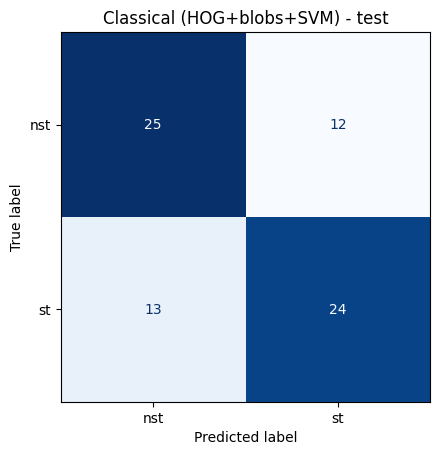

In [34]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay, PrecisionRecallDisplay

FE = {s: np.stack([classical_features(im) for im in DATA[s]["imgs"]]) for s in ("train", "val", "test")}
# TODO: choose C for the SVM using the VALIDATION set only.
# For each C in (0.1, 1, 10, 100): fit make_pipeline(StandardScaler(), SVC(C=C, kernel="rbf", random_state=SEED))
# on FE["train"], measure accuracy on FE["val"], print it, keep the best model.
# At the end the variable CLF must hold the chosen fitted pipeline.
best_acc = -1

for C in (0.1, 1, 10, 100):
    clf = make_pipeline(StandardScaler(),
                        SVC(C=C, kernel="rbf", random_state=SEED))

    clf.fit(FE["train"], DATA["train"]["y"])

    acc = clf.score(FE["val"], DATA["val"]["y"])
    print("C =", C, "Accuracy =", acc)

    if acc > best_acc:
        best_acc = acc
        CLF = clf

def classical_predict(imgs, clf=None):
    F = np.stack([classical_features(im) for im in imgs]); clf = clf or CLF
    p = clf.decision_function(F); return (p >= 0).astype(int), p   # signed distance to the SVM margin

def report(y, pred, title):
    print(title); print(classification_report(y, pred, target_names=[NEG_NAME, POS_NAME], digits=3))
    ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=[NEG_NAME, POS_NAME]).plot(cmap="Blues", colorbar=False)
    plt.title(title); plt.show()

pred_c, _ = classical_predict(DATA["test"]["imgs"])
report(DATA["test"]["y"], pred_c, "Classical (HOG+blobs+SVM) - test")

## Part 3 – YOLO baseline

model classes: {0: 'nst', 1: 'st'}
positive class index in model: 1
YOLO11n-cls - test (original)
              precision    recall  f1-score   support

         nst      1.000     0.811     0.896        37
          st      0.841     1.000     0.914        37

    accuracy                          0.905        74
   macro avg      0.920     0.905     0.905        74
weighted avg      0.920     0.905     0.905        74



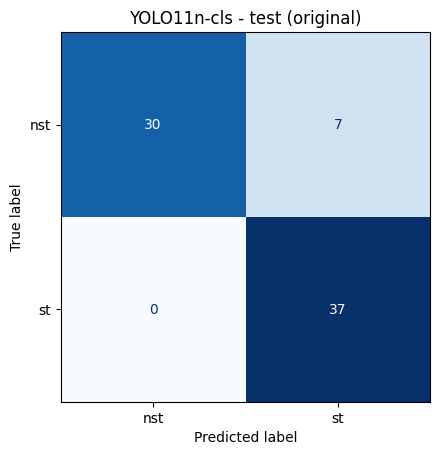

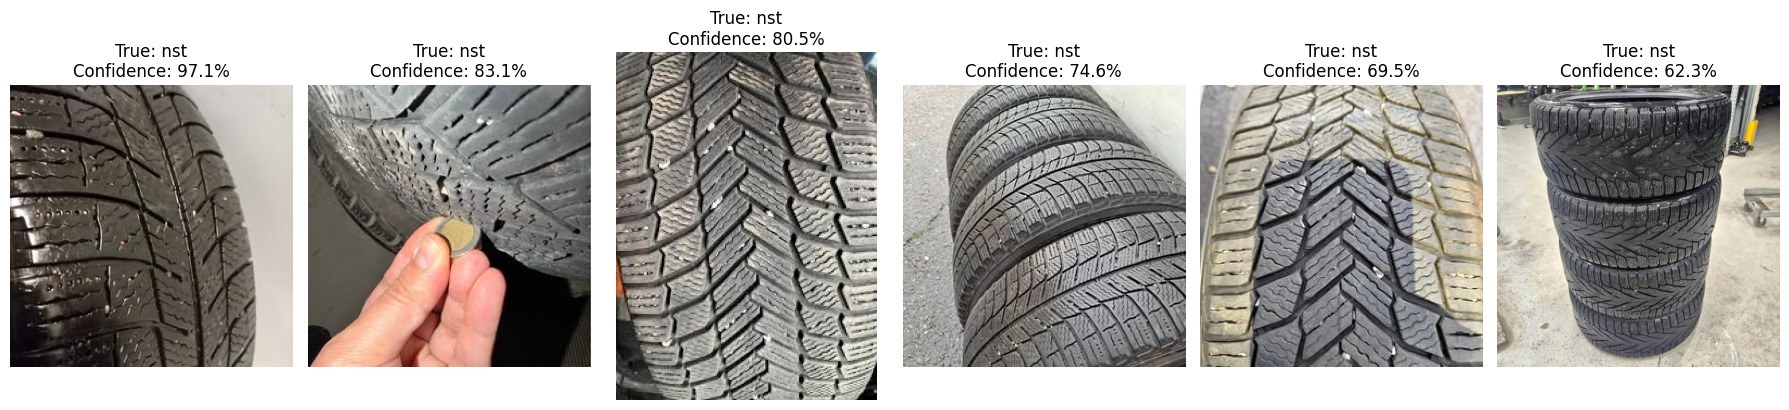

{'YOLO11n-cls': '19.2 ms/image', 'Classical (HOG+SVM)': '11.1 ms/image'}


In [35]:
from ultralytics import YOLO
model = YOLO(MODEL_PATH)
print("model classes:", model.names)
# map model class index -> our label via class name (falls back to sorted order)
name2idx = {norm(n): i for i, n in model.names.items()}
POS_IDX = name2idx.get(norm(POS_NAME), CLASS_NAMES.index(POS_NAME))
print("positive class index in model:", POS_IDX)

def yolo_predict(imgs, batch=32):
    P = []
    for i in range(0, len(imgs), batch):
        P += [r.probs.data.cpu().numpy() for r in model.predict(imgs[i:i + batch], device="cpu", verbose=False)]
    P = np.stack(P); return (P.argmax(1) == POS_IDX).astype(int), P[:, POS_IDX]

y_te = DATA["test"]["y"]
pred_y, p_y = yolo_predict(DATA["test"]["imgs"])
report(y_te, pred_y, "YOLO11n-cls - test (original)")

# TODO: show the 6 most confident WRONG predictions of YOLO on the test set in one row.
# Available: y_te (true labels), pred_y (predicted labels), p_y (P(studded)), DATA["test"]["imgs"].
# Title each image with its true class and the confidence of the wrong prediction.
# Then answer the question below.
wrong = np.where(y_te != pred_y)[0]
confidence = np.where(pred_y == 1, p_y, 1 - p_y)
worst = wrong[np.argsort(confidence[wrong])[::-1][:6]]

fig, ax = plt.subplots(1, 6, figsize=(18, 4))

for a in ax:
    a.axis("off")

for j, i in enumerate(worst):
    ax[j].imshow(cv2.cvtColor(DATA["test"]["imgs"][i],
                              cv2.COLOR_BGR2RGB))
    ax[j].set_title(f"True: {POS_NAME if y_te[i] else NEG_NAME}\n"
                    f"Confidence: {confidence[i]:.1%}")

plt.tight_layout()
plt.show()

# inference time (CPU, single image)
def ms_per_image(fn, imgs, n=50):
    fn(imgs[:2]); t = time.perf_counter()
    for im in imgs[:n]: fn([im])
    return 1000 * (time.perf_counter() - t) / min(n, len(imgs))
TIMES = {"YOLO11n-cls": ms_per_image(yolo_predict, DATA["test"]["imgs"]),
         "Classical (HOG+SVM)": ms_per_image(classical_predict, DATA["test"]["imgs"])}
print({k: f"{v:.1f} ms/image" for k, v in TIMES.items()})

**Write:** what do the confidently-wrong images have in common?

✏️ **Your answer:**

YOLO achieved an accuracy of 90.5%. It correctly classified all studded tires but incorrectly classified seven non-studded tires.

The wrong predictions have complex tread patterns, small holes and bright spots that could be confused with studs.

YOLO needed 19.2 ms per image, while the classical classifier needed 11.1 ms per image. YOLO is slower but more accurate.

## Part 4 – Simulating the real world (degradations)
Applied to **val and test** (val is needed to tune Wiener K). Fixed seed per image. Blur PSF is a **1×L horizontal line** (every element 1/L).
Order of the physical model: blur → darkening (gamma) → sensor noise.

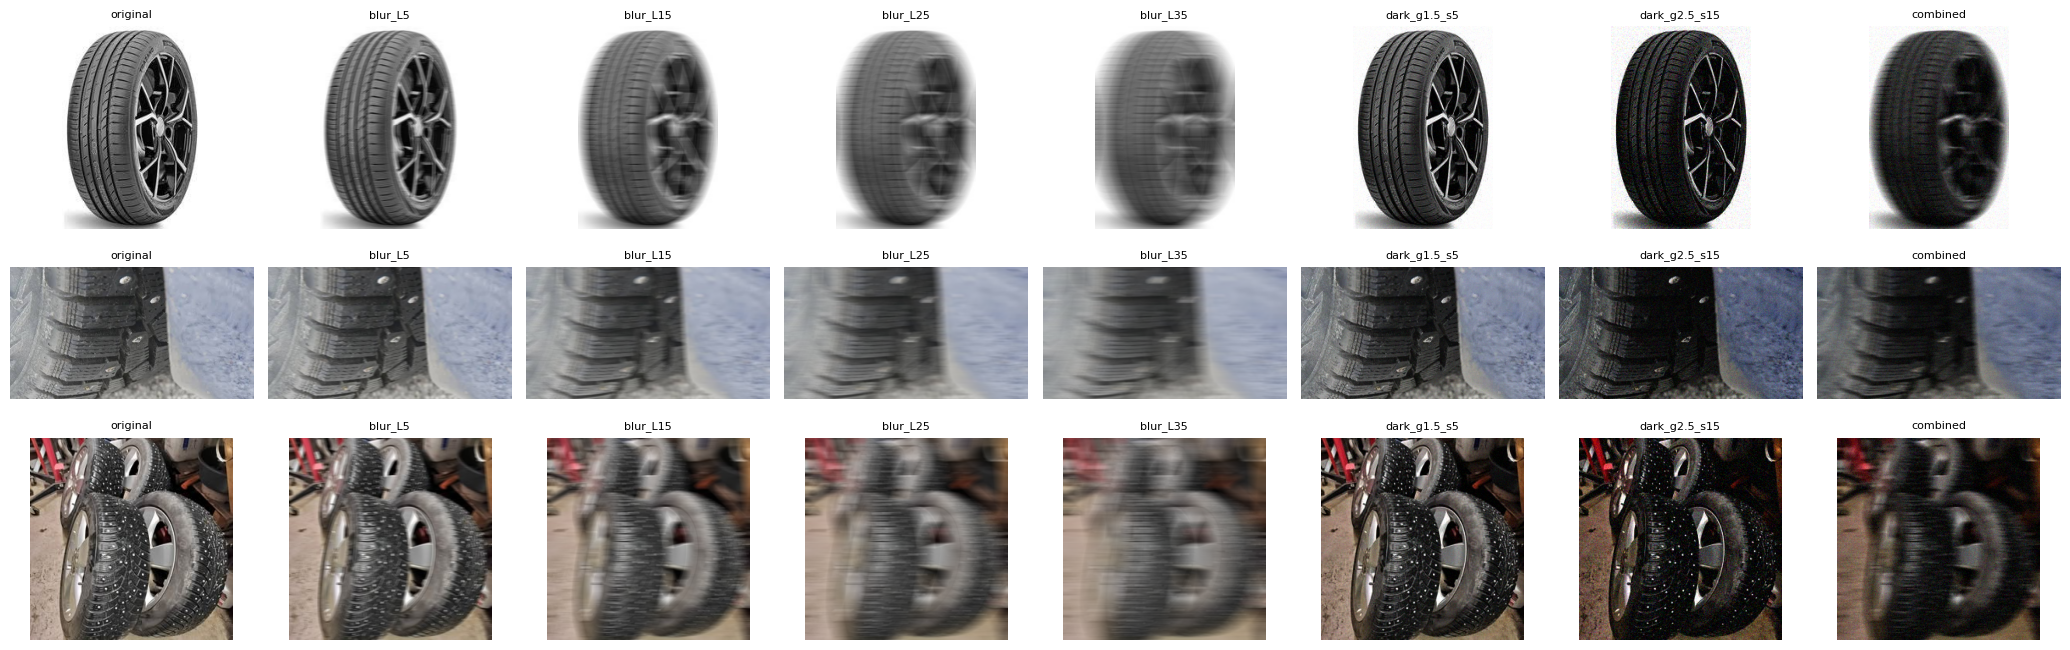

,condition,PSNR (dB),SSIM
0,blur_L5,23.896,0.759
1,blur_L15,19.726,0.461
2,blur_L25,18.492,0.376
3,blur_L35,17.784,0.335
4,dark_g1.5_s5,18.579,0.836
5,dark_g2.5_s15,12.187,0.420
6,combined,12.630,0.250


In [38]:
CONDS = build_conditions()
DEG = {s: {c: degrade_set(DATA[s]["imgs"], f) for c, f in CONDS.items()} for s in ("val", "test")}

# save to disk (data/blur, data/lowlight, data/combined) - originals are never touched
def folder_of(c): return "blur" if c.startswith("blur") else "lowlight" if c.startswith("dark") else c
def save_set(split, cond, imgs, root):
    for im, p, y in zip(imgs, DATA[split]["paths"], DATA[split]["y"]):
        d = WORK / root / cond / split / (POS_NAME if y else NEG_NAME); d.mkdir(parents=True, exist_ok=True)
        cv2.imwrite(str(d / (p.stem + ".png")), im)
for c in CONDS:
    if c != "original": save_set("test", c, DEG["test"][c], folder_of(c))

# before/after grid + PSNR/SSIM
show = [c for c in CONDS if c != "original"]; sel = [0, len(y_te) // 2, len(y_te) - 1]
fig, ax = plt.subplots(len(sel), len(show) + 1, figsize=(2.6 * (len(show) + 1), 2.2 * len(sel)))
for r, i in enumerate(sel):
    ax[r, 0].imshow(cv2.cvtColor(DATA["test"]["imgs"][i], cv2.COLOR_BGR2RGB)); ax[r, 0].set_title("original", fontsize=8)
    for c, name in enumerate(show, 1):
        ax[r, c].imshow(cv2.cvtColor(DEG["test"][name][i], cv2.COLOR_BGR2RGB)); ax[r, c].set_title(name, fontsize=8)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()
rows = []
for c in show:
    v = np.array([psnr_ssim(o, d) for o, d in zip(DATA["test"]["imgs"], DEG["test"][c])]); rows.append((c, *v.mean(0)))
display(pd.DataFrame(rows, columns=["condition", "PSNR (dB)", "SSIM"]).round(3))

## Part 5 – Restoration
* Wiener deconvolution (own FFT implementation, `wiener_deconv`) with the **known** kernel; K tuned on **validation**.
* Wiener with a **mismatched** kernel (true L = 15, assumed 9 and 21).
* Low-light restoration: inverse gamma + denoising + CLAHE.

,K,Mean PSNR (dB)
0,0.0001,17.854857
1,0.0003,19.515862
2,0.0010,21.179979
3,0.0030,22.245516
4,0.0100,22.498137
5,0.0300,21.838375
6,0.1000,19.803772


Best K: 0.01


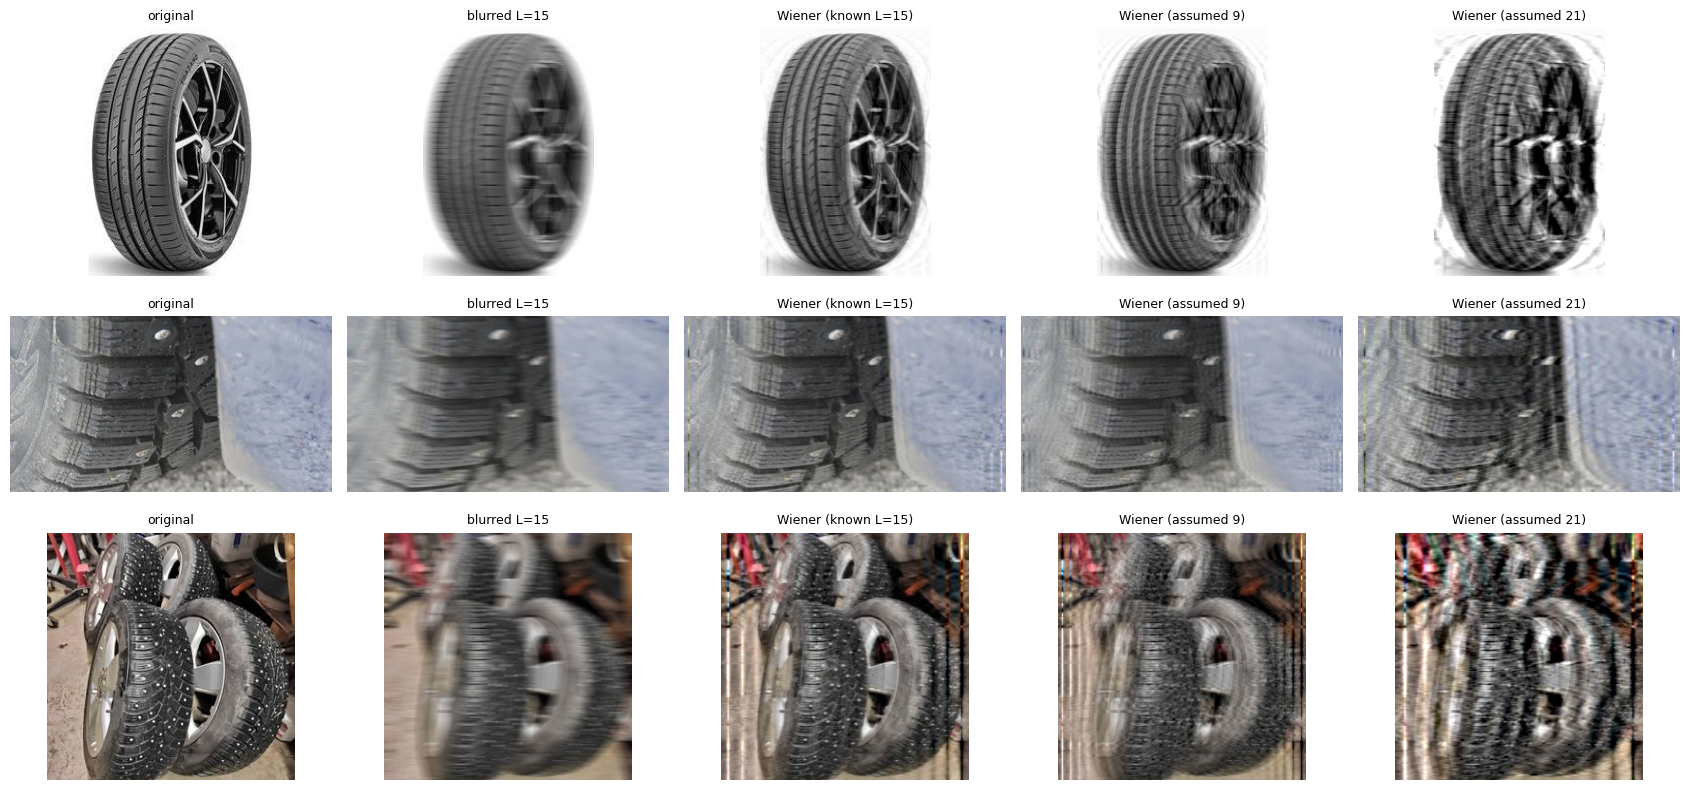

,condition,PSNR before,SSIM before,PSNR after,SSIM after
0,blur_L5,23.896,0.759,27.725,0.922
1,blur_L15,19.726,0.461,22.303,0.740
2,blur_L25,18.492,0.376,20.048,0.624
3,blur_L35,17.784,0.335,18.800,0.548
4,dark_g1.5_s5,18.579,0.836,19.397,0.830
5,dark_g2.5_s15,12.187,0.420,15.340,0.580
6,combined,12.630,0.250,12.353,0.302


In [41]:
# tune K on validation (blur_L15)
Ks = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1]
# TODO: for each K in Ks, restore every VALIDATION blur_L15 image with wiener_deconv(d, motion_psf(15), K) and compute the
# mean PSNR against the original validation image (psnr_ssim(o, restored)[0]). Show a table of K vs. mean PSNR,
# then set K_BEST to the K with the highest mean PSNR.
scores = []

for K in Ks:
    values = []

    for o, d in zip(DATA["val"]["imgs"], DEG["val"]["blur_L15"]):
        restored = wiener_deconv(d, motion_psf(15), K)
        values.append(psnr_ssim(o, restored)[0])

    scores.append(np.mean(values))

display(pd.DataFrame({"K": Ks, "Mean PSNR (dB)": scores}))

K_BEST = Ks[np.argmax(scores)]
print("Best K:", K_BEST)

# ---- restoration functions per condition (used in Part 6) ----
def restore(cond, im):
    if cond.startswith("blur"):     return wiener_deconv(im, motion_psf(int(cond.split("L")[1])), K_BEST)
    if cond.startswith("dark"):     return restore_lowlight(im, float(cond.split("_g")[1].split("_")[0]))
    if cond == "combined":          return restore_lowlight(wiener_deconv(im, motion_psf(15), K_BEST), 2.0)
    return im
RES = {c: [restore(c, im) for im in DEG["test"][c]] for c in CONDS if c != "original"}
for c in RES: save_set("test", c, RES[c], f"restored")

# 3 examples: original / blurred / restored / mismatched 9 / mismatched 21
fig, ax = plt.subplots(3, 5, figsize=(17, 8))
for r, i in enumerate(sel):
    b = DEG["test"]["blur_L15"][i]
    ims = [DATA["test"]["imgs"][i], b, RES["blur_L15"][i], wiener_deconv(b, motion_psf(9), K_BEST), wiener_deconv(b, motion_psf(21), K_BEST)]
    for c, (t, im) in enumerate(zip(["original", "blurred L=15", "Wiener (known L=15)", "Wiener (assumed 9)", "Wiener (assumed 21)"], ims)):
        ax[r, c].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax[r, c].set_title(t, fontsize=9); ax[r, c].axis("off")
plt.tight_layout(); plt.show()

rows = []
for c in RES:
    pre = np.array([psnr_ssim(o, d) for o, d in zip(DATA["test"]["imgs"], DEG["test"][c])]).mean(0)
    post = np.array([psnr_ssim(o, d) for o, d in zip(DATA["test"]["imgs"], RES[c])]).mean(0)
    rows.append((c, *pre, *post))
display(pd.DataFrame(rows, columns=["condition", "PSNR before", "SSIM before", "PSNR after", "SSIM after"]).round(3))

**Write:** does higher PSNR always mean a better-looking (or more classifiable) image? Note that CLAHE changes global contrast on purpose, so PSNR against the original can drop even when studs become *easier* to see.

✏️ **Your answer:**
**K tuning:**

I selected K = 0.01 because it achieved the highest mean PSNR of 22.498 dB on the validation set.

**Wrong kernel:**

The correct kernel (L = 15) gives better results. Wrong kernels create artefacts and repeated edges.

**Restoration:**

PSNR and SSIM improved for most conditions. For the combined condition, PSNR decreased while SSIM increased.

A higher PSNR does not always mean a better-looking image or better classification. Important details, such as studs, can still be lost.

## Part 6 – Robustness experiment
Both classifiers × every condition × {no preprocessing, CLAHE only, matched restoration}. The CLAHE and restoration columns for YOLO are the **hybrid test**.

In [42]:
def prep(kind, cond, imgs_deg, i0=None):
    if kind == "none":   return imgs_deg
    if kind == "clahe":  return [clahe_bgr(im) for im in imgs_deg]
    if kind == "restore": return RES[cond] if cond in RES else imgs_deg

RESULTS, PRED = [], {}
for cond in CONDS:
    for kind in ("none", "clahe", "restore"):
        if cond == "original" and kind == "restore": continue
        imgs = prep(kind, cond, DEG["test"][cond])
        for name, fn in (("YOLO", yolo_predict), ("Classical", classical_predict)):
            pr, sc = fn(imgs); PRED[(name, cond, kind)] = (pr, sc)
            lo, hi = bootstrap_ci(y_te, pr)
            RESULTS.append(dict(classifier=name, condition=cond, preprocessing=kind, **metrics(y_te, pr), acc_CI_low=lo, acc_CI_high=hi))
R = pd.DataFrame(RESULTS); R.to_csv(WORK / "results.csv", index=False)
display(R.round(3))

,classifier,condition,preprocessing,accuracy,precision,recall,f1,acc_CI_low,acc_CI_high
0,YOLO,original,none,0.905,0.841,1.000,0.914,0.838,0.960
1,Classical,original,none,0.662,0.667,0.649,0.658,0.554,0.770
2,YOLO,original,clahe,0.878,0.938,0.811,0.870,0.797,0.946
3,Classical,original,clahe,0.635,0.632,0.649,0.640,0.527,0.743
4,YOLO,blur_L5,none,0.905,0.969,0.838,0.899,0.838,0.973
5,Classical,blur_L5,none,0.662,0.773,0.459,0.576,0.554,0.770
6,YOLO,blur_L5,clahe,0.851,1.000,0.703,0.825,0.770,0.932
7,Classical,blur_L5,clahe,0.662,0.714,0.541,0.615,0.554,0.770
8,YOLO,blur_L5,restore,0.932,0.921,0.946,0.933,0.878,0.986
9,Classical,blur_L5,restore,0.608,0.611,0.595,0.603,0.486,0.716


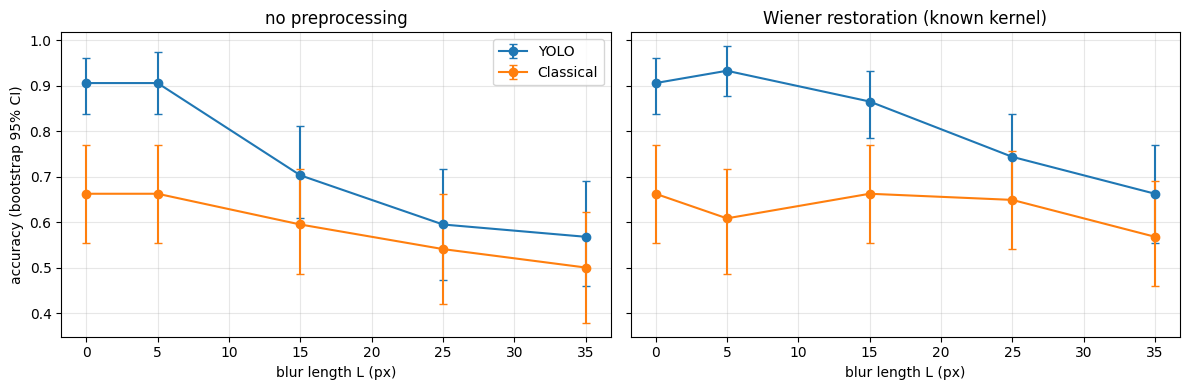

,condition,preprocessing,accuracy,precision,recall,f1,acc_CI_low,acc_CI_high
0,original,none,0.905,0.841,1.000,0.914,0.838,0.960
2,original,clahe,0.878,0.938,0.811,0.870,0.797,0.946
10,blur_L15,none,0.703,0.826,0.514,0.633,0.608,0.811
12,blur_L15,clahe,0.676,0.842,0.432,0.571,0.568,0.784
14,blur_L15,restore,0.865,0.966,0.757,0.848,0.784,0.932
40,combined,none,0.662,0.714,0.541,0.615,0.554,0.770
42,combined,clahe,0.581,0.636,0.378,0.475,0.473,0.690
44,combined,restore,0.649,0.824,0.378,0.519,0.541,0.757


In [43]:
# accuracy vs blur length (no preprocessing and with Wiener)
Ls = [0, 5, 15, 25, 35]; cn = lambda L: "original" if L == 0 else f"blur_L{L}"
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, kind in zip(ax, ("none", "restore")):
    for name in ("YOLO", "Classical"):
        rows = [R[(R.classifier == name) & (R.condition == cn(L)) & (R.preprocessing == ("none" if L == 0 else kind))].iloc[0] for L in Ls]
        acc = np.array([r.accuracy for r in rows]); lo = np.array([r.acc_CI_low for r in rows]); hi = np.array([r.acc_CI_high for r in rows])
        a.errorbar(Ls, acc, yerr=[acc - lo, hi - acc], marker="o", capsize=3, label=name)
    a.set_title("no preprocessing" if kind == "none" else "Wiener restoration (known kernel)"); a.set_xlabel("blur length L (px)"); a.grid(alpha=.3)
ax[0].set_ylabel("accuracy (bootstrap 95% CI)"); ax[0].legend(); plt.tight_layout(); plt.show()

# summary table required by the assignment
main = R[(R.classifier == "YOLO") & R.condition.isin(["original", "blur_L15", "combined"])]
display(main[["condition", "preprocessing", "accuracy", "precision", "recall", "f1", "acc_CI_low", "acc_CI_high"]].round(3))

**Interpreting the CIs:** with a small test set the 95% intervals are wide. Two accuracies are only *meaningfully different* if their intervals barely overlap (a paired bootstrap on the same images is stricter, optional extension). Say explicitly which differences in your table are meaningful.

✏️ **Your answer:**

The difference between YOLO and the classical classifier is meaningful for the original images, blur L5, blur L5 and L15 with Wiener restoration, and both low-light conditions with CLAHE.

For stronger blur and the combined condition, the confidence intervals overlap. Therefore, the differences are less clear.

The test set contains only 74 images, which explains the wide confidence intervals.

## Part 7 – Engineering decision: threshold and speed
A false positive fines an innocent driver; a false negative lets a studded tire through. Choose the operating point on the **validation** set, then report it once on test.

threshold for >=95% precision on val: 0.476


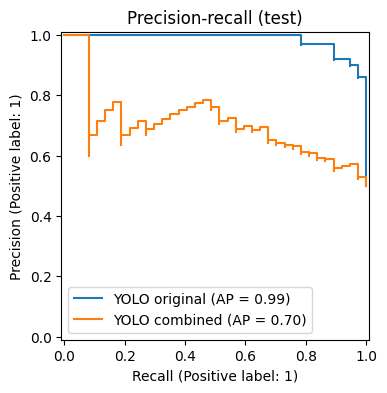

original {'accuracy': 0.905, 'precision': 0.841, 'recall': 1.0, 'f1': 0.914}
blur_L15 {'accuracy': 0.703, 'precision': 0.826, 'recall': 0.514, 'f1': 0.633}
combined {'accuracy': 0.662, 'precision': 0.7, 'recall': 0.568, 'f1': 0.627}
{'YOLO11n-cls': 19.210081880009966, 'Classical (HOG+SVM)': 11.094605179969221}


In [44]:
_, p_val = yolo_predict(DATA["val"]["imgs"]); y_val = DATA["val"]["y"]
T = threshold_for_precision(y_val, p_val, target=0.95); print(f"threshold for >=95% precision on val: {T:.3f}")
fig, ax = plt.subplots(figsize=(5, 4))
PrecisionRecallDisplay.from_predictions(y_te, p_y, ax=ax, name="YOLO original")
PrecisionRecallDisplay.from_predictions(y_te, PRED[("YOLO", "combined", "none")][1], ax=ax, name="YOLO combined")
plt.title("Precision-recall (test)"); plt.show()
for cond in ("original", "blur_L15", "combined"):
    pr = (PRED[("YOLO", cond, "none")][1] >= T).astype(int)
    print(cond, {k: round(v, 3) for k, v in metrics(y_te, pr).items()})
print(TIMES)

**Memo (400–600 words, in README):** recommended system with numbers; which error is worse and your threshold; at what blur length / light level the system stops being reliable; edge feasibility from the measured ms/image; what data you would collect next.

## Bonus – Challenge track
Replace `challenge_pipeline` with your best classical preprocessing. The instructor runs it on a **hidden degraded test set**.

✏️ **Your answer:**

I tested three different preprocessing pipelines on the validation set:

- CLAHE: 57.9% accuracy
- Gamma correction + CLAHE: 55.3% accuracy
- Gamma correction + Wiener restoration: 65.8% accuracy

I chose the third pipeline because it achieved the highest validation accuracy. Gamma correction makes the image brighter, and Wiener restoration reduces motion blur.

In [49]:
def challenge_pipeline(bgr):
    # TODO (students): any classical operations, any order. Must return a BGR uint8 image of the same size.
    out = darken(bgr, 0.7)
    return wiener_deconv(out, motion_psf(15), K_BEST)

pr, _ = yolo_predict([challenge_pipeline(im) for im in DEG["val"]["combined"]])
print("val accuracy on combined condition with your pipeline:", round(accuracy_score(DATA["val"]["y"], pr), 3))

val accuracy on combined condition with your pipeline: 0.658
